In [1]:
!pip install -q dcm2niix monai

In [2]:
import os, shutil, subprocess, warnings
import numpy as np
import pandas as pd
import torch
import monai.transforms as T
import matplotlib.pyplot as plt
from concurrent.futures import ThreadPoolExecutor, as_completed
from tqdm import tqdm

warnings.filterwarnings("ignore")
torch.set_num_threads(1)

OUT_DIR = "/kaggle/working/preprocessed"
TMP_DIR = "/tmp/nifti"
MAX_GB = 18

ORIENTATION = "LPS"
SPACING = (1.0, 1.0, 1.0)
SIZE = (192, 192, 192)
CT_WINDOW = (0, 900)

os.makedirs(OUT_DIR, exist_ok=True)
os.makedirs(TMP_DIR, exist_ok=True)


import glob

candidates = glob.glob("/kaggle/input/*/train.csv") + glob.glob("/kaggle/input/*/*/train.csv")
BASE = next(os.path.dirname(p) for p in candidates
            if os.path.isdir(os.path.join(os.path.dirname(p), "series")))
SERIES_DIR = os.path.join(BASE, "series")
print(BASE)


def select_series(modalities=("CTA", "MRA")):
    train = pd.read_csv(os.path.join(BASE, "train.csv"))
    df = train[train["Modality"].isin(modalities)].reset_index(drop=True)
    print(len(df), df["Modality"].value_counts().to_dict())
    return df

/kaggle/input/competitions/rsna-intracranial-aneurysm-detection


In [3]:
def base_transforms(modality):
    if modality == "CTA":
        intensity = T.ScaleIntensityRanged(keys="image", a_min=CT_WINDOW[0], a_max=CT_WINDOW[1],
                                           b_min=-1.0, b_max=1.0, clip=True)
    else:
        intensity = T.NormalizeIntensityd(keys="image", nonzero=True)

    return T.Compose([
        T.LoadImaged(keys="image"),
        T.EnsureChannelFirstd(keys="image"),
        T.Orientationd(keys="image", axcodes=ORIENTATION, labels=(("L", "R"), ("P", "A"), ("I", "S"))),
        T.CropForegroundd(keys="image", source_key="image"),
        T.Spacingd(keys="image", pixdim=SPACING, mode="bilinear"),
        intensity,
        T.EnsureTyped(keys="image"),
    ])


def crop_or_pad(volume, size=SIZE):
    out = np.full(size, volume.min(), dtype=np.float32)
    src, dst = [], []
    for axis, (n, s) in enumerate(zip(volume.shape, size)):
        length = min(n, s)
        if axis == 2:
            src_start = n - length
        else:
            src_start = (n - length) // 2
        dst_start = (s - length) // 2
        src.append(slice(src_start, src_start + length))
        dst.append(slice(dst_start, dst_start + length))
    out[tuple(dst)] = volume[tuple(src)]
    return out

In [4]:
def preprocess_series(uid, modality):
    tmp = os.path.join(TMP_DIR, uid)
    os.makedirs(tmp, exist_ok=True)
    entry = {"uid": uid, "modality": modality, "ok": False, "n_files": 0,
             "shape": None, "spacing_varies": False, "message": ""}
    try:
        result = subprocess.run(["dcm2niix", "-z", "n", "-b", "n", "-f", uid, "-o", tmp, os.path.join(SERIES_DIR, uid)], capture_output=True, text=True)
        entry["spacing_varies"] = "varies" in result.stdout.lower()
        files = [f for f in os.listdir(tmp) if f.endswith(".nii")]
        entry["n_files"] = len(files)
        if not files:
            entry["message"] = result.stdout[-300:]
            return entry
        biggest = max(files, key=lambda f: os.path.getsize(os.path.join(tmp, f)))
        data = base_transforms(modality)({"image": os.path.join(tmp, biggest)})
        volume = np.asarray(data["image"][0], dtype=np.float32)
        entry["shape"] = volume.shape
        volume = crop_or_pad(volume)
        np.save(os.path.join(OUT_DIR, f"{uid}.npy"), volume.astype(np.float16))
        entry["ok"] = True
    except Exception as e:
        entry["message"] = str(e)[:300]
    finally:
        shutil.rmtree(tmp, ignore_errors=True)
    return entry

In [5]:
def folder_size_gb(folder):
    total = 0
    for entry in os.scandir(folder):
        try:
            total += entry.stat().st_size
        except FileNotFoundError:
            pass
    return total / 1024**3


def run_chunk(df, start, end, max_gb=MAX_GB, workers=4):
    chunk = df.iloc[start:end]
    todo = [r for _, r in chunk.iterrows() if not os.path.exists(os.path.join(OUT_DIR, f"{r['SeriesInstanceUID']}.npy"))]
    log = []
    with ThreadPoolExecutor(max_workers=workers) as pool:
        futures = [pool.submit(preprocess_series, r["SeriesInstanceUID"], r["Modality"]) for r in todo]
        for future in tqdm(as_completed(futures), total=len(futures)):
            log.append(future.result())
            if folder_size_gb(OUT_DIR) > max_gb:
                print(f"[STOP] am atins {max_gb} GB; anulez restul")
                for f in futures:
                    f.cancel()
                break
    log = pd.DataFrame(log)
    log["label"] = log["uid"].map(df.set_index("SeriesInstanceUID")["Aneurysm Present"])
    log.to_csv(f"/kaggle/working/log_{start}_{end}.csv", index=False)
    print(log.groupby("modality")["ok"].value_counts())
    return log


def check_outputs(n=3):
    files = sorted(os.listdir(OUT_DIR))[:n]
    fig, axes = plt.subplots(n, 3, figsize=(9, 3 * n), squeeze=False)
    for row, f in zip(axes, files):
        v = np.load(os.path.join(OUT_DIR, f)).astype(np.float32)
        print(f, v.shape, round(float(v.min()), 2), round(float(v.max()), 2))
        row[0].imshow(v[:, :, v.shape[2] // 2].T, cmap="gray")
        row[1].imshow(v[:, v.shape[1] // 2, :].T, cmap="gray", origin="lower")
        row[2].imshow(v[v.shape[0] // 2, :, :].T, cmap="gray", origin="lower")
    plt.tight_layout()
    plt.savefig("/kaggle/working/check.png")
    plt.show()

In [6]:
df = select_series()
df = df.sort_values(["Modality", "SeriesInstanceUID"], ascending=[False, True]).reset_index(drop=True)
print(df["Modality"].iloc[:1252].value_counts())
print(df["Modality"].iloc[1252:].value_counts())

3060 {'CTA': 1808, 'MRA': 1252}
Modality
MRA    1252
Name: count, dtype: int64
Modality
CTA    1808
Name: count, dtype: int64


  0%|          | 0/1252 [00:00<?, ?it/s]nvImageCodec is not available; skipping pydicom decoder plugin registration.
nvImageCodec is not available; skipping pydicom decoder plugin registration.
nvImageCodec is not available; skipping pydicom decoder plugin registration.
  0%|          | 4/1252 [00:09<47:21,  2.28s/it]nvImageCodec is not available; skipping pydicom decoder plugin registration.
nvImageCodec is not available; skipping pydicom decoder plugin registration.
  1%|          | 7/1252 [00:14<37:07,  1.79s/it]nvImageCodec is not available; skipping pydicom decoder plugin registration.
nvImageCodec is not available; skipping pydicom decoder plugin registration.
nvImageCodec is not available; skipping pydicom decoder plugin registration.
  1%|          | 12/1252 [00:20<21:40,  1.05s/it]nvImageCodec is not available; skipping pydicom decoder plugin registration.
nvImageCodec is not available; skipping pydicom decoder plugin registration.
  1%|          | 13/1252 [00:22<30:00,  1.45s

modality  ok  
MRA       True    1252
Name: count, dtype: int64
     modality    ok            shape  spacing_varies message
0         MRA  True   (222, 264, 83)           False        
1         MRA  True  (189, 229, 103)           False        
2         MRA  True   (180, 180, 94)           False        
3         MRA  True   (202, 240, 83)           False        
4         MRA  True  (200, 220, 168)           False        
...       ...   ...              ...             ...     ...
1247      MRA  True   (179, 229, 99)           False        
1248      MRA  True   (176, 211, 87)           False        
1249      MRA  True   (156, 200, 92)           False        
1250      MRA  True  (180, 180, 113)           False        
1251      MRA  True   (156, 200, 92)           False        

[1252 rows x 5 columns]
1.2.826.0.1.3680043.8.498.10004044428023505108375152878107656647.npy (192, 192, 192) -1.31 18.34
1.2.826.0.1.3680043.8.498.10004684224894397679901841656954650085.npy (192, 192, 19

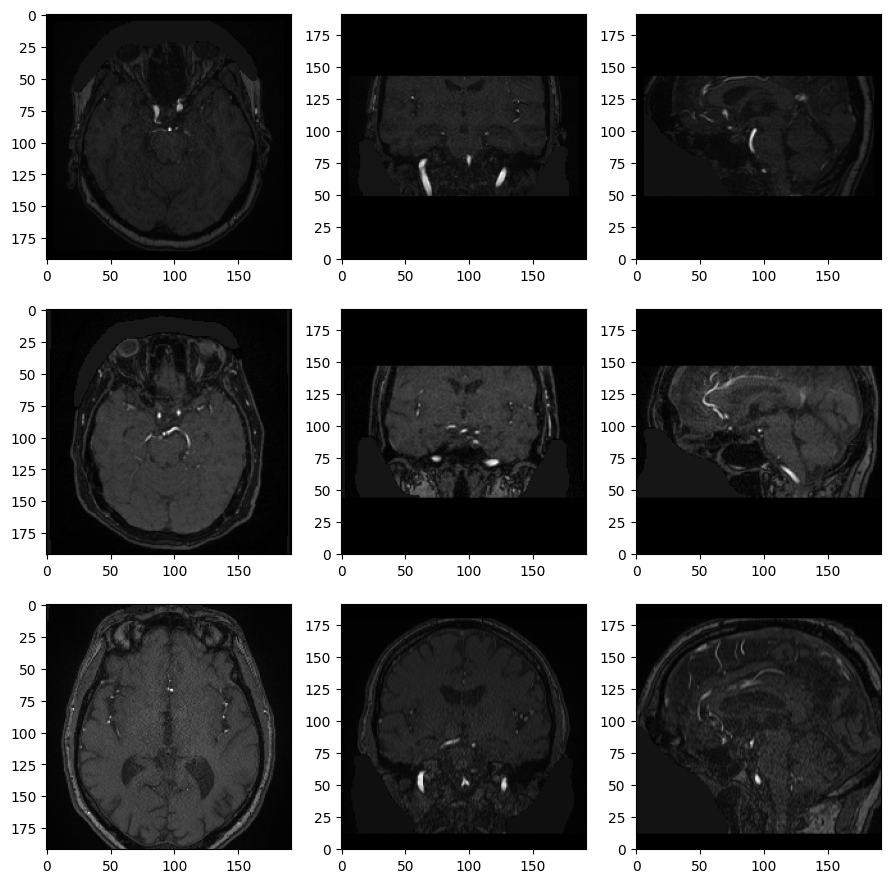

In [7]:
shutil.rmtree(OUT_DIR); os.makedirs(OUT_DIR)
log = run_chunk(df, start=0, end=1252)
print(log[["modality", "ok", "shape", "spacing_varies", "message"]])
check_outputs()

In [8]:
import nibabel as nib, pydicom, glob

uid = "1.2.826.0.1.3680043.8.498.10021411248005513321236647460239137906"
tmp = "/tmp/debug"
os.makedirs(tmp, exist_ok=True)
subprocess.run(["dcm2niix", "-z", "n", "-b", "n", "-f", uid, "-o", tmp, os.path.join(SERIES_DIR, uid)],
               capture_output=True)
for f in os.listdir(tmp):
    a = np.asanyarray(nib.load(os.path.join(tmp, f)).dataobj)
    print(f, a.shape, np.percentile(a, [1, 50, 99]).round())

d = pydicom.dcmread(sorted(glob.glob(os.path.join(SERIES_DIR, uid, "*.dcm")))[0], stop_before_pixels=True)
print(d.get("RescaleIntercept"), d.get("RescaleSlope"), d.get("Manufacturer"), d.get("ImageType"))

1.2.826.0.1.3680043.8.498.10021411248005513321236647460239137906.nii (512, 512, 239) [-2044. -2002.   410.]
1.2.826.0.1.3680043.8.498.10021411248005513321236647460239137906_Eq_1.nii (512, 512, 241) [-2044. -2002.   407.]
-1024 1 SIEMENS ['ORIGINAL', 'PRIMARY', 'AXIAL', 'CT_SOM5 SPI DUAL', 'STD', 'DNRG', 'DET_AB']
